In [6]:
import csv
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from rdkit import Chem

In [10]:
# Load in molecule data
molecule_data = pd.read_csv('../data/raw/CHEMBL_30_10_2026.csv', sep='";"', engine="python", quoting=csv.QUOTE_NONE)

# The first column header/values start with ", the last end with ".
molecule_data.columns = molecule_data.columns.str.strip('"').str.strip()
for col in (molecule_data.columns[0], molecule_data.columns[-1]):
    molecule_data[col] = molecule_data[col].astype("string").str.strip('"')

molecule_data = molecule_data.rename(
        columns={"Compound ChEMBL ID": "ChEMBL ID"})

# Load in experimental data
experimental_data = pd.read_csv('../data/raw/CHEMBL_01_11_2026.csv', sep='";"', engine="python", quoting=csv.QUOTE_NONE)

experimental_data.columns = experimental_data.columns.str.strip('"').str.strip()
for col in (molecule_data.columns[0], molecule_data.columns[-1]):
    molecule_data[col] = molecule_data[col].astype("string").str.strip('"')

experimental_data = experimental_data.rename(
        columns={"Molecule ChEMBL ID": "ChEMBL ID"})

mol_cols = ["ChEMBL ID"] + [c for c in molecule_data.columns
                                if c not in experimental_data.columns and c != "ChEMBL ID"]

data = experimental_data.merge(molecule_data[mol_cols], on="ChEMBL ID", how="left",
                     validate="many_to_one", indicator=True)
print(data.shape)

# Remove empty columns
for column in data.columns:
    if data[column].isna().sum() == len(data):
        data = data.drop(column, axis = 'columns')

print(data.shape)
print(data.isna().sum())


(4200, 74)
(4200, 25)
ChEMBL ID                 0
Molecule Name          3549
Molecule Max Phase     3624
Molecular Weight          0
#RO5 Violations          11
AlogP                    11
Compound Key              0
Smiles                    0
Standard Type             0
Standard Value            0
Potential Duplicate       0
Assay ChEMBL ID           0
Assay Description         0
Assay Type                0
BAO Format ID             0
BAO Label                 0
Target ChEMBL ID          0
Target Name               0
Target Type               0
Document ChEMBL ID        0
Source ID                 0
Source Name               0
Value                     0
Modality                  0
_merge                    0
dtype: int64


In [11]:
print(data["Standard Type"].value_counts())
print(data["Assay ChEMBL ID"].nunique(), data["Document ChEMBL ID"].nunique())
print(data["Assay ChEMBL ID"].value_counts().head())
print(pd.to_numeric(data["Standard Value"], errors="coerce").describe())
print((pd.to_numeric(data["Standard Value"], errors="coerce") == pd.to_numeric(data["Value"], errors="coerce")).mean())
print(data["Potential Duplicate"].value_counts())
print(data["ChEMBL ID"].duplicated().sum())

Standard Type
LogD7.4    4200
Name: count, dtype: int64
1 1
Assay ChEMBL ID
CHEMBL3301363    4200
Name: count, dtype: int64
count    4200.000000
mean        2.186336
std         1.203004
min        -1.500000
25%         1.410000
50%         2.360000
75%         3.100000
max         4.500000
Name: Standard Value, dtype: float64
1.0
Potential Duplicate
0    4200
Name: count, dtype: int64
5


Type
Small molecule    5784
Protein              9
Unknown              1
Name: count, dtype: int64


KeyError: 'Type'

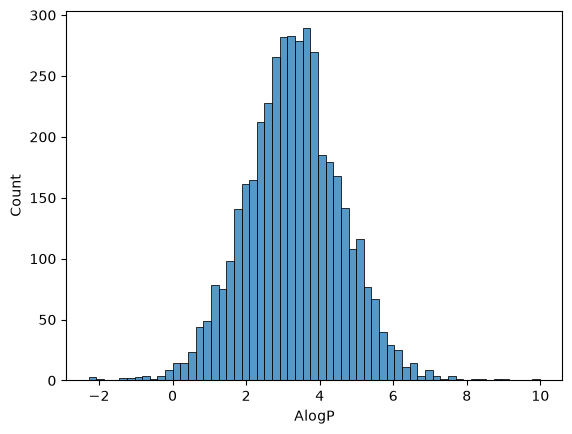

In [13]:
# Explore target variable distribution
sns.histplot(data = data, x = 'AlogP')

# Explore entry types
print(molecule_data['Type'].value_counts(dropna = False))

# Remove entries of non-small molecules
data_clean = data[data['Type'] == 'Small molecule']
data_clean = data[['ChEMBL ID', 'Smiles', 'AlogP']]
print(data.shape)


In [16]:
# with no H, Cl, Br or I attached.
_CF3 = Chem.MolFromSmarts("[CX4;H0](F)(F)F")
_CF2 = Chem.MolFromSmarts("[CX4;H0](F)(F)([!#9;!#17;!#35;!#53])[!#9;!#17;!#35;!#53]")


def fluorine_stats(smiles) -> pd.DataFrame:
    rows = []
    for s in smiles:
        m = Chem.MolFromSmiles(s)
        carbons = ({x[0] for x in m.GetSubstructMatches(_CF3)}
                   | {x[0] for x in m.GetSubstructMatches(_CF2)})
        rows.append({"n_F": sum(a.GetAtomicNum() == 9 for a in m.GetAtoms()),
                     "n_cf_carbons": len(carbons)})
    out = pd.DataFrame(rows)
    out["pfas_oecd"] = out["n_cf_carbons"] > 0
    return out

fs = fluorine_stats(data["Smiles"])
print(pd.cut(fs["n_cf_carbons"], [-1, 0, 1, 3, 10_000], labels=["0", "1", "2-3", "4+"]).value_counts().sort_index())
print(data.loc[fs["n_cf_carbons"] >= 2, "Smiles"].head(10).tolist())

n_cf_carbons
0      3893
1       290
2-3      17
4+        0
Name: count, dtype: int64
['Fc1cccc(C(COCc2cc(C(F)(F)F)cc(C(F)(F)F)c2)N2CCNCC2)c1', 'CC(C)C(NC(=O)Cn1c(-c2cccs2)ncc(NC(=O)OCC(F)(F)F)c1=O)C(=O)C(F)(F)F', 'FC(F)(F)c1cc(CO[C@H]2CCCN[C@H]2c2ccccc2)cc(C(F)(F)F)c1', 'CC(C)C(NC(=O)Cn1c(-c2ccccc2)ncc(NC(=O)OCC(F)(F)F)c1=O)C(=O)C(F)(F)F', 'NC(=O)c1cc(C(N)=O)n(-c2cccc(-c3cc(C(F)(F)F)ccc3C(F)(F)F)c2)n1', 'C[C@H]1O[C@@H](n2cnc3c(N)nc(OCC4CC(F)(F)C4(F)F)nc32)[C@H](O)[C@@H]1O', 'O=C(Nc1cc(C(F)(F)F)cc(C(F)(F)F)c1)c1cnc(Cl)nc1C(F)(F)F', 'FC(F)(F)c1cc(COCC(c2ccccc2)N2CCNCC2)cc(C(F)(F)F)c1', 'Fc1ccc(C(COCc2cc(C(F)(F)F)cc(C(F)(F)F)c2)N2CCNCC2)cc1', 'O=S(=O)(c1ccccc1)N(CC(F)(F)F)c1ccc(C(O)(C(F)(F)F)C(F)(F)F)cc1']
